# Customer Segmentation and Purchase Prediction
### Project 2 — End-to-End Data Analytics Learning Project

**Industry:** Customer Analytics / Insurance  
**Dataset:** `customer_segmentation_data.csv`  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

**Workflow:** Data Understanding → Cleaning → Statistical Analysis → EDA → Feature Engineering → K-Means → Prediction → Evaluation → Business Insights

Check the CSV path in Section 1 before running.

## 1. Setup and Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, silhouette_score,
    average_precision_score, precision_score, recall_score, f1_score
)

sns.set_theme(style="whitegrid")
df = pd.read_csv(r"C:\Users\ASUS\Downloads\customer_segmentation_data.csv")
df.columns = df.columns.str.strip()
print("Loaded:", df.shape)
display(df.head())

Loaded: (53503, 20)


,Customer ID,Age,Gender,Marital Status,Education Level,Geographic Information,Occupation,Income Level,Behavioral Data,Purchase History,Interactions with Customer Service,Insurance Products Owned,Coverage Amount,Premium Amount,Policy Type,Customer Preferences,Preferred Communication Channel,Preferred Contact Time,Preferred Language,Segmentation Group
0,84966,23,Female,Married,Associate Degree,Mizoram,Entrepreneur,70541,policy5,04-10-2018,Phone,policy2,366603,2749,Group,Email,In-Person Meeting,Afternoon,English,Segment5
1,95568,26,Male,Widowed,Doctorate,Goa,Manager,54168,policy5,11-06-2018,Chat,policy1,780236,1966,Group,Mail,In-Person Meeting,Morning,French,Segment5
2,10544,29,Female,Single,Associate Degree,Rajasthan,Entrepreneur,73899,policy5,06-05-2021,Email,policy3,773926,4413,Group,Email,Mail,Evening,German,Segment3
3,77033,20,Male,Divorced,Bachelor's Degree,Sikkim,Entrepreneur,63381,policy5,09-02-2018,Chat,policy2,787815,4342,Family,Text,In-Person Meeting,Anytime,French,Segment3
4,88160,25,Female,Separated,Bachelor's Degree,West Bengal,Manager,38794,policy1,09-10-2018,Chat,policy4,366506,1276,Family,Email,Text,Weekends,English,Segment2


## 2. Data Understanding
Inspect dimensions, columns, data types, and sample records.

In [2]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("\nColumns:", df.columns.tolist())
df.info()
display(df.head())
display(df.sample(min(5, len(df)), random_state=42))

Rows: 53503 | Columns: 20

Columns: ['Customer ID', 'Age', 'Gender', 'Marital Status', 'Education Level', 'Geographic Information', 'Occupation', 'Income Level', 'Behavioral Data', 'Purchase History', 'Interactions with Customer Service', 'Insurance Products Owned', 'Coverage Amount', 'Premium Amount', 'Policy Type', 'Customer Preferences', 'Preferred Communication Channel', 'Preferred Contact Time', 'Preferred Language', 'Segmentation Group']
<class 'pandas.DataFrame'>
RangeIndex: 53503 entries, 0 to 53502
Data columns (total 20 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   Customer ID                         53503 non-null  int64
 1   Age                                 53503 non-null  int64
 2   Gender                              53503 non-null  str  
 3   Marital Status                      53503 non-null  str  
 4   Education Level                     53503 non-null  str  
 5   Geograph

,Customer ID,Age,Gender,Marital Status,Education Level,Geographic Information,Occupation,Income Level,Behavioral Data,Purchase History,Interactions with Customer Service,Insurance Products Owned,Coverage Amount,Premium Amount,Policy Type,Customer Preferences,Preferred Communication Channel,Preferred Contact Time,Preferred Language,Segmentation Group
0,84966,23,Female,Married,Associate Degree,Mizoram,Entrepreneur,70541,policy5,04-10-2018,Phone,policy2,366603,2749,Group,Email,In-Person Meeting,Afternoon,English,Segment5
1,95568,26,Male,Widowed,Doctorate,Goa,Manager,54168,policy5,11-06-2018,Chat,policy1,780236,1966,Group,Mail,In-Person Meeting,Morning,French,Segment5
2,10544,29,Female,Single,Associate Degree,Rajasthan,Entrepreneur,73899,policy5,06-05-2021,Email,policy3,773926,4413,Group,Email,Mail,Evening,German,Segment3
3,77033,20,Male,Divorced,Bachelor's Degree,Sikkim,Entrepreneur,63381,policy5,09-02-2018,Chat,policy2,787815,4342,Family,Text,In-Person Meeting,Anytime,French,Segment3
4,88160,25,Female,Separated,Bachelor's Degree,West Bengal,Manager,38794,policy1,09-10-2018,Chat,policy4,366506,1276,Family,Email,Text,Weekends,English,Segment2


,Customer ID,Age,Gender,Marital Status,Education Level,Geographic Information,Occupation,Income Level,Behavioral Data,Purchase History,Interactions with Customer Service,Insurance Products Owned,Coverage Amount,Premium Amount,Policy Type,Customer Preferences,Preferred Communication Channel,Preferred Contact Time,Preferred Language,Segmentation Group
36995,26433,37,Male,Married,Doctorate,Mizoram,Lawyer,50891,policy4,06-11-2023,Chat,policy1,941997,3381,Family,Phone,Text,Morning,French,Segment5
2778,27624,51,Female,Married,Master's Degree,Chandigarh,Salesperson,107339,policy4,3/22/2023,Chat,policy3,748863,3396,Family,Phone,Mail,Anytime,English,Segment1
30309,21370,26,Female,Separated,Master's Degree,Rajasthan,Engineer,36083,policy4,10-04-2018,Mobile App,policy1,773961,2295,Group,Text,Email,Anytime,Spanish,Segment4
40956,75794,29,Female,Divorced,Doctorate,Nagaland,Teacher,41122,policy5,10-12-2022,Email,policy4,597673,720,Group,In-Person Meeting,Text,Evening,French,Segment5
27077,97315,31,Male,Divorced,Bachelor's Degree,Arunachal Pradesh,Artist,132965,policy1,1/16/2022,In-Person,policy5,658409,4443,Family,Mail,Phone,Weekends,French,Segment2


## 3. Data Cleaning
Remove exact duplicates and inspect missing values.

In [3]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Duplicates after:", df.duplicated().sum())
display(df.isnull().sum().to_frame("Missing Values"))
display((df.isnull().mean() * 100).round(2).to_frame("Missing Percentage"))
df.info()

Duplicates before: 0
Duplicates after: 0


,Missing Values
Customer ID,0
Age,0
Gender,0
Marital Status,0
Education Level,0
Geographic Information,0
Occupation,0
Income Level,0
Behavioral Data,0
Purchase History,0


,Missing Percentage
Customer ID,0.0
Age,0.0
Gender,0.0
Marital Status,0.0
Education Level,0.0
Geographic Information,0.0
Occupation,0.0
Income Level,0.0
Behavioral Data,0.0
Purchase History,0.0


<class 'pandas.DataFrame'>
RangeIndex: 53503 entries, 0 to 53502
Data columns (total 20 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   Customer ID                         53503 non-null  int64
 1   Age                                 53503 non-null  int64
 2   Gender                              53503 non-null  str  
 3   Marital Status                      53503 non-null  str  
 4   Education Level                     53503 non-null  str  
 5   Geographic Information              53503 non-null  str  
 6   Occupation                          53503 non-null  str  
 7   Income Level                        53503 non-null  int64
 8   Behavioral Data                     53503 non-null  str  
 9   Purchase History                    53503 non-null  str  
 10  Interactions with Customer Service  53503 non-null  str  
 11  Insurance Products Owned            53503 non-null  str  
 12  Coverage Amount

## 4. Statistical Analysis
Calculate descriptive statistics and review the existing segment distribution.

In [4]:
display(df.describe(include=[np.number]).T.round(2))
for col in ["Age", "Income Level", "Premium Amount", "Coverage Amount"]:
    if col in df.columns:
        print(f"{col}: mean={df[col].mean():,.2f}, median={df[col].median():,.2f}")
if "Segmentation Group" in df.columns:
    display(df["Segmentation Group"].value_counts(dropna=False).to_frame("Count"))
    display((df["Segmentation Group"].value_counts(normalize=True, dropna=False)*100)
            .round(2).to_frame("Percentage"))

,count,mean,std,min,25%,50%,75%,max
Customer ID,53503.0,52265.20,28165.00,1.0,28950.5,55858.0,76096.0,100000.0
Age,53503.0,44.14,15.08,18.0,32.0,43.0,57.0,70.0
Income Level,53503.0,82768.32,36651.08,20001.0,51568.5,80719.0,115973.5,149999.0
Coverage Amount,53503.0,492580.79,268405.51,50001.0,249613.5,477261.0,739124.0,1000000.0
Premium Amount,53503.0,3023.70,1285.83,500.0,1817.0,3194.0,4311.5,5000.0


Age: mean=44.14, median=43.00
Income Level: mean=82,768.32, median=80,719.00
Premium Amount: mean=3,023.70, median=3,194.00
Coverage Amount: mean=492,580.79, median=477,261.00


,Count
Segmentation Group,
Segment5,13976
Segment2,11442
Segment4,10125
Segment3,9277
Segment1,8683


,Percentage
Segmentation Group,
Segment5,26.12
Segment2,21.39
Segment4,18.92
Segment3,17.34
Segment1,16.23


## 5. Exploratory Data Analysis (EDA)
Visualize numerical distributions, existing segments, and correlations.

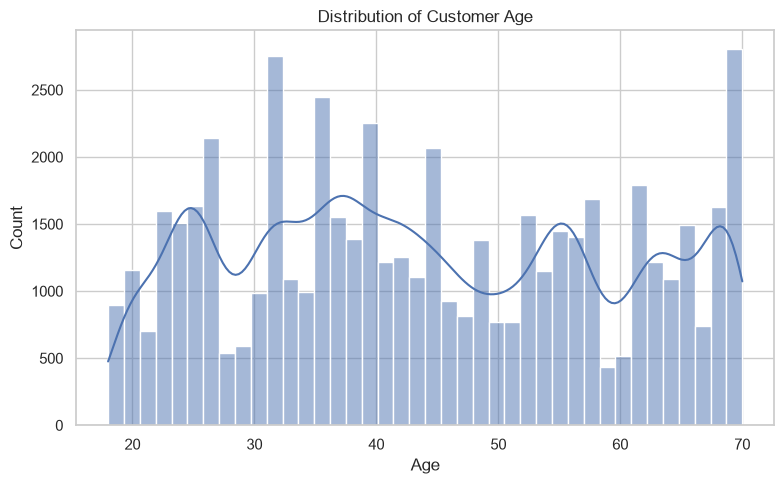

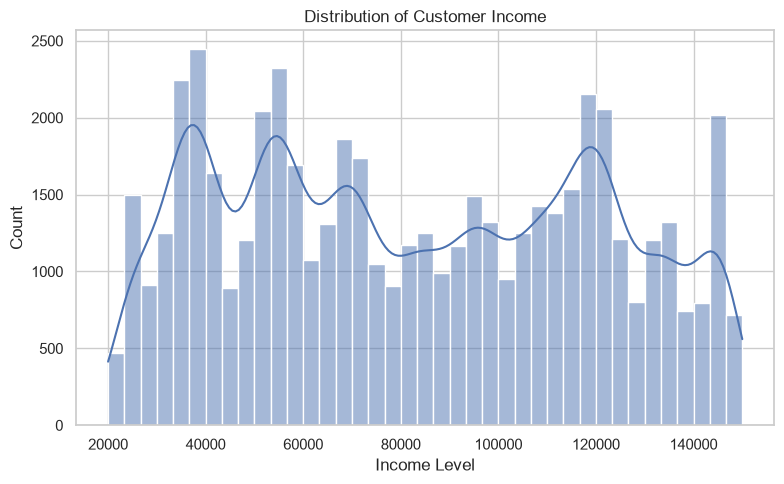

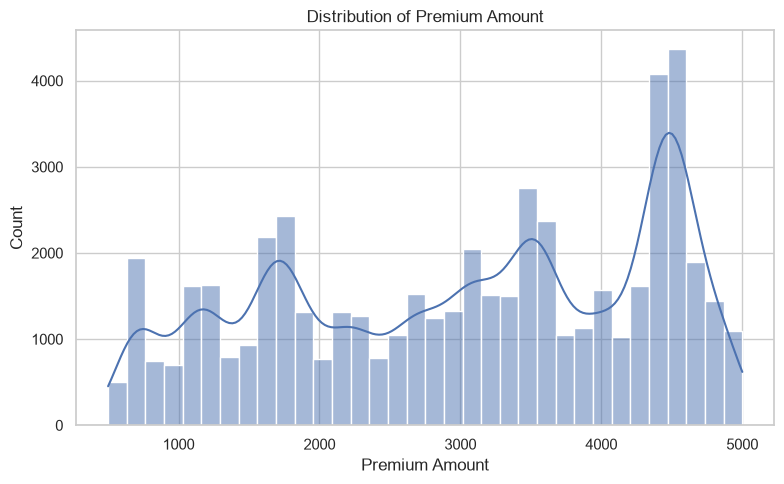

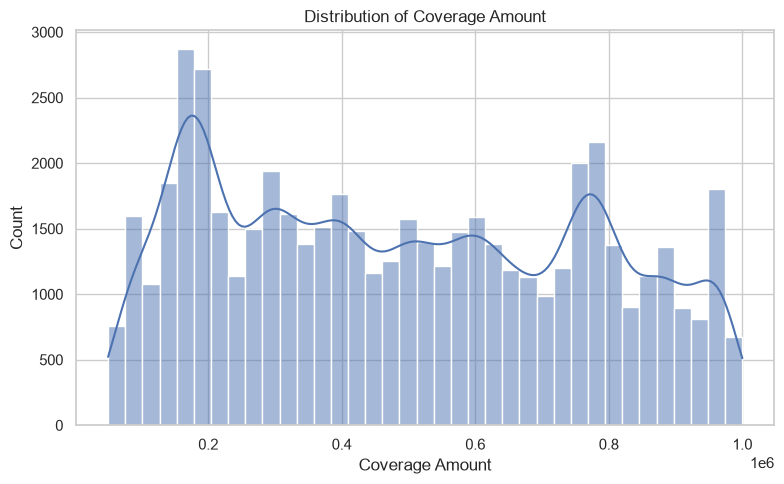

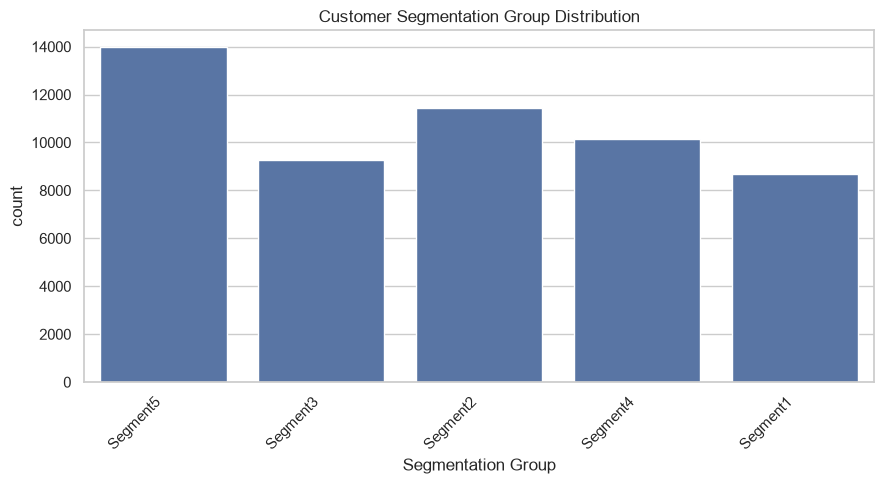

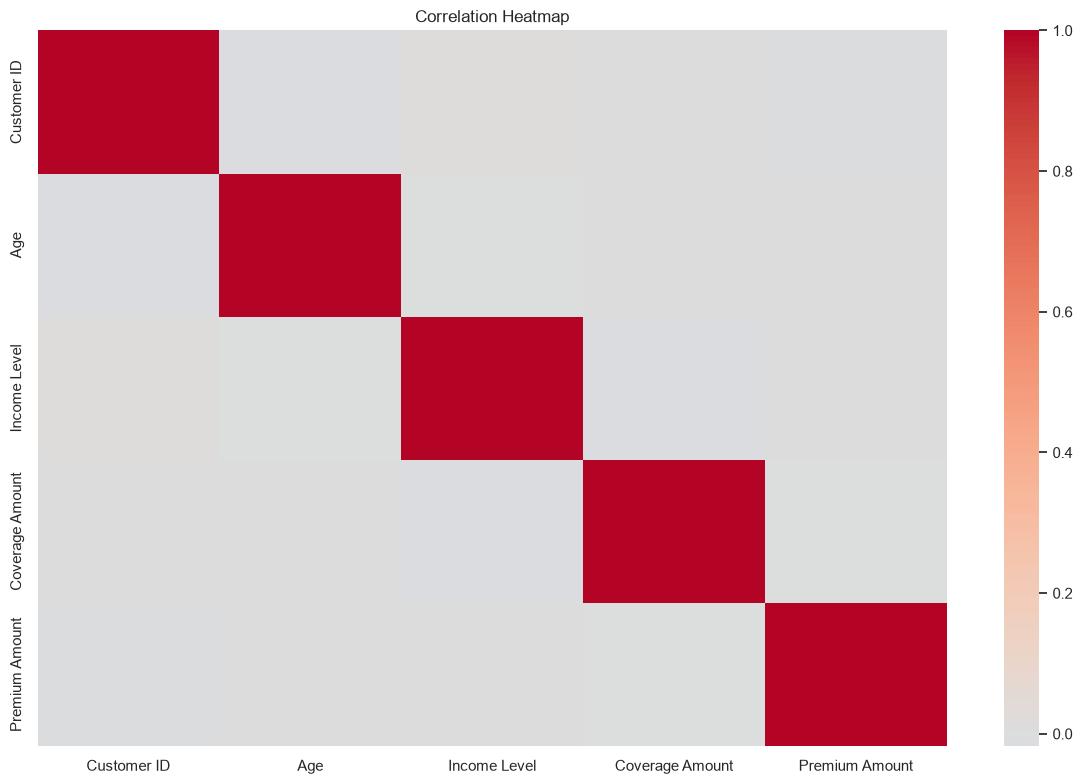

In [5]:
for col, title in [
    ("Age", "Distribution of Customer Age"),
    ("Income Level", "Distribution of Customer Income"),
    ("Premium Amount", "Distribution of Premium Amount"),
    ("Coverage Amount", "Distribution of Coverage Amount")
]:
    if col in df.columns:
        plt.figure(figsize=(8,5))
        sns.histplot(data=df, x=col, kde=True)
        plt.title(title); plt.tight_layout(); plt.show()

if "Segmentation Group" in df.columns:
    plt.figure(figsize=(9,5))
    sns.countplot(data=df, x="Segmentation Group")
    plt.title("Customer Segmentation Group Distribution")
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

num_df = df.select_dtypes(include=np.number)
if num_df.shape[1] > 1:
    plt.figure(figsize=(12,8))
    sns.heatmap(num_df.corr(), cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()

## 6. Feature Engineering and Preprocessing
Create age groups, premium categories, and income ratios once.

In [6]:
required = ["Age", "Income Level", "Premium Amount", "Coverage Amount"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

df["Age Group"] = pd.cut(
    df["Age"], bins=[17,25,35,45,55,65,float("inf")],
    labels=["18-25","26-35","36-45","46-55","56-65","65+"]
)
df["Premium Income Ratio"] = np.where(
    df["Income Level"] > 0, df["Premium Amount"] / df["Income Level"], np.nan
)
df["Coverage Income Ratio"] = np.where(
    df["Income Level"] > 0, df["Coverage Amount"] / df["Income Level"], np.nan
)
df["Premium Category"] = pd.cut(
    df["Premium Amount"], bins=[-float("inf"),2000,4000,float("inf")],
    labels=["Low","Medium","High"]
)
display(df[["Age","Age Group","Income Level","Premium Amount",
            "Premium Income Ratio","Coverage Income Ratio","Premium Category"]].head())
display(df[["Age Group","Premium Income Ratio","Coverage Income Ratio","Premium Category"]]
        .isnull().sum().to_frame("Missing Values"))

,Age,Age Group,Income Level,Premium Amount,Premium Income Ratio,Coverage Income Ratio,Premium Category
0,23,18-25,70541,2749,0.038970,5.197020,Medium
1,26,26-35,54168,1966,0.036294,14.404002,Low
2,29,26-35,73899,4413,0.059717,10.472753,High
3,20,18-25,63381,4342,0.068506,12.429829,High
4,25,18-25,38794,1276,0.032892,9.447492,Low


,Missing Values
Age Group,0
Premium Income Ratio,0
Coverage Income Ratio,0
Premium Category,0


## 7. Customer Segmentation Using K-Means
Scale numerical features, cluster customers, and inspect cluster profiles.

,Customer Count
Customer Cluster,
0,13707
1,18185
2,21611


Silhouette Score: 0.199


,Customer_Count,Average_Age,Average_Income,Average_Coverage,Average_Premium
Customer Cluster,,,,,
0,13707,44.15,43025.34,618842.29,3564.92
1,18185,44.21,89401.26,489524.67,1588.89
2,21611,44.07,102394.31,415069.76,3887.78


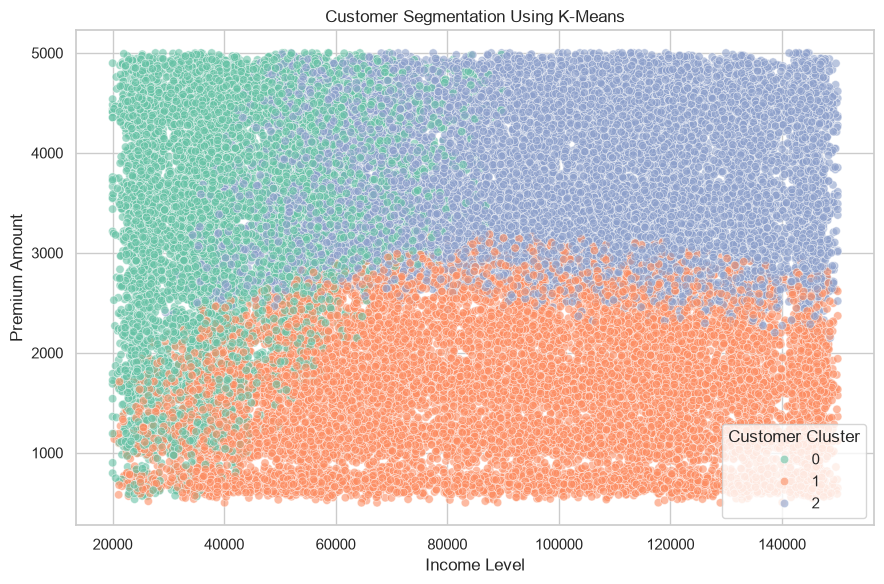

In [7]:
numeric_features = [
    "Age","Income Level","Coverage Amount","Premium Amount",
    "Premium Income Ratio","Coverage Income Ratio"
]
X_cluster = df[numeric_features].replace([np.inf,-np.inf], np.nan)
X_cluster = X_cluster.fillna(X_cluster.median())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Customer Cluster"] = kmeans.fit_predict(X_scaled)
display(df["Customer Cluster"].value_counts().sort_index().to_frame("Customer Count"))

if df["Customer Cluster"].nunique() > 1 and len(df) > 3:
    print("Silhouette Score:", round(silhouette_score(
        X_scaled, df["Customer Cluster"],
        sample_size=min(5000, len(df)), random_state=42
    ), 3))

count_col = ("Customer ID", "count") if "Customer ID" in df.columns else ("Age", "count")
cluster_summary = df.groupby("Customer Cluster").agg(
    Customer_Count=count_col, Average_Age=("Age","mean"),
    Average_Income=("Income Level","mean"),
    Average_Coverage=("Coverage Amount","mean"),
    Average_Premium=("Premium Amount","mean")
).round(2)
display(cluster_summary)

plt.figure(figsize=(9,6))
sns.scatterplot(data=df, x="Income Level", y="Premium Amount",
                hue="Customer Cluster", palette="Set2", alpha=0.6)
plt.title("Customer Segmentation Using K-Means")
plt.tight_layout(); plt.show()

## 8. Customer Segmentation Prediction
Train one Random Forest pipeline to predict the existing `Segmentation Group` label.

Review potential target leakage: engineered features may be related to the existing label.
Training rows: 42802 | Testing rows: 10701
Accuracy: 0.2575
Balanced accuracy: 0.2535
              precision    recall  f1-score   support

    Segment1       0.21      0.25      0.23      1737
    Segment2       0.25      0.21      0.23      2289
    Segment3       0.22      0.24      0.23      1855
    Segment4       0.24      0.25      0.25      2025
    Segment5       0.33      0.32      0.32      2795

    accuracy                           0.26     10701
   macro avg       0.25      0.25      0.25     10701
weighted avg       0.26      0.26      0.26     10701



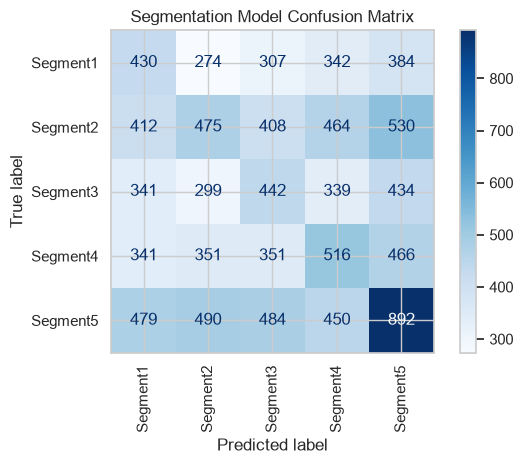

,Actual Segment,Predicted Segment
497,Segment2,Segment4
38846,Segment5,Segment5
12582,Segment3,Segment5
18469,Segment4,Segment1
30515,Segment2,Segment5
15736,Segment3,Segment3
49813,Segment2,Segment3
46582,Segment5,Segment2
23817,Segment2,Segment1
19016,Segment3,Segment2


,Feature,Importance
2,num__Coverage Amount,0.040335
4,num__Premium Income Ratio,0.039287
3,num__Premium Amount,0.038523
0,num__Age,0.037674
5,num__Coverage Income Ratio,0.037418
1,num__Income Level,0.035348
2091,cat__Insurance Products Owned_policy5,0.016294
66,cat__Behavioral Data_policy5,0.012224
2099,cat__Customer Preferences_Phone,0.011921
2084,cat__Interactions with Customer Service_In-Person,0.011630


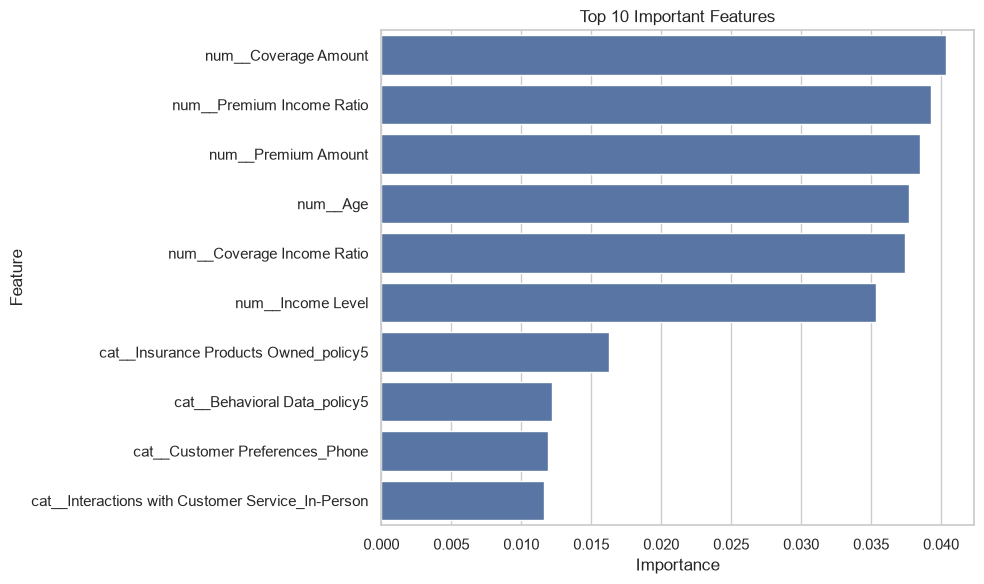

In [8]:
if "Segmentation Group" not in df.columns:
    raise KeyError("Required target column 'Segmentation Group' not found.")

y = df["Segmentation Group"]
X = df.drop(columns=["Segmentation Group","Customer ID","Customer Cluster"], errors="ignore").copy()
valid = y.notna()
X, y = X.loc[valid].copy(), y.loc[valid].copy()

print("Review potential target leakage: engineered features may be related to the existing label.")
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])
segmentation_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200, max_depth=15, min_samples_leaf=5,
        class_weight="balanced", random_state=42, n_jobs=-1
    ))
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
segmentation_model.fit(X_train, y_train)
y_pred = segmentation_model.predict(X_test)

print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test,y_pred),4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test,y_pred),4))
print(classification_report(y_test,y_pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,xticks_rotation="vertical",cmap="Blues")
plt.title("Segmentation Model Confusion Matrix"); plt.tight_layout(); plt.show()
display(pd.DataFrame({"Actual Segment":y_test,"Predicted Segment":y_pred}).head(10))

names = segmentation_model.named_steps["preprocessor"].get_feature_names_out()
importances = segmentation_model.named_steps["classifier"].feature_importances_
feature_importance = pd.DataFrame({"Feature":names,"Importance":importances}).sort_values(
    "Importance", ascending=False
)
display(feature_importance.head(10))
plt.figure(figsize=(10,6))
sns.barplot(data=feature_importance.head(10),x="Importance",y="Feature")
plt.title("Top 10 Important Features"); plt.tight_layout(); plt.show()

## 9. Future Purchase Prediction

This exploratory model uses the next recorded purchase date as a target. **Important limitation:** rows without a later recorded purchase are excluded, so this does not represent all customers or prove real-world predictive performance.

In [9]:
if "Purchase History" not in df.columns or "Customer ID" not in df.columns:
    print("Skipped: Purchase History or Customer ID column is missing.")
    purchase_model = None
else:
    purchase_df = df.copy()
    purchase_df["Purchase History"] = pd.to_datetime(purchase_df["Purchase History"], errors="coerce")
    purchase_df = purchase_df.dropna(subset=["Customer ID","Purchase History"])
    purchase_df = purchase_df.drop_duplicates(subset=["Customer ID","Purchase History"])
    purchase_df = purchase_df.sort_values(["Customer ID","Purchase History"])
    purchase_df["Next Purchase Date"] = purchase_df.groupby("Customer ID")["Purchase History"].shift(-1)
    purchase_df = purchase_df.dropna(subset=["Next Purchase Date"]).copy()
    purchase_df["Days Until Next Purchase"] = (
        purchase_df["Next Purchase Date"] - purchase_df["Purchase History"]
    ).dt.days
    purchase_df["Future Purchase"] = (purchase_df["Days Until Next Purchase"] <= 30).astype(int)

    print("Rows available for exploratory target:", len(purchase_df))
    display(purchase_df["Future Purchase"].value_counts().to_frame("Count"))

    if len(purchase_df) > 10 and purchase_df["Future Purchase"].nunique() > 1:
        drop_cols = ["Customer ID","Purchase History","Next Purchase Date",
                     "Days Until Next Purchase","Future Purchase",
                     "Segmentation Group","Customer Cluster"]
        Xp = purchase_df.drop(columns=drop_cols, errors="ignore")
        yp = purchase_df["Future Purchase"]
        date_cols = Xp.select_dtypes(include=["datetime","datetimetz"]).columns.tolist()
        Xp = Xp.drop(columns=date_cols, errors="ignore")
        ncols = Xp.select_dtypes(include=np.number).columns.tolist()
        ccols = Xp.select_dtypes(exclude=np.number).columns.tolist()

        pprep = ColumnTransformer([
            ("num", SimpleImputer(strategy="median"), ncols),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]), ccols)
        ])
        purchase_model = Pipeline([
            ("preprocessor", pprep),
            ("classifier", RandomForestClassifier(
                n_estimators=300, max_depth=10, min_samples_leaf=5,
                class_weight="balanced", random_state=42, n_jobs=-1
            ))
        ])
        X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
            Xp, yp, test_size=0.2, random_state=42, stratify=yp
        )
        purchase_model.fit(X_train_p,y_train_p)
        purchase_pred = purchase_model.predict(X_test_p)
        purchase_prob = purchase_model.predict_proba(X_test_p)[:,1]

        print("Balanced accuracy:", round(balanced_accuracy_score(y_test_p,purchase_pred),4))
        print("Average precision:", round(average_precision_score(y_test_p,purchase_prob),4))
        print(confusion_matrix(y_test_p,purchase_pred))
        print(classification_report(y_test_p,purchase_pred,zero_division=0))

        prediction_results = pd.DataFrame({
            "Actual Future Purchase": y_test_p.to_numpy(),
            "Predicted Future Purchase": purchase_pred,
            "Purchase Probability": purchase_prob
        }, index=y_test_p.index)
        display(prediction_results.head())
        prediction_results.to_csv("Future_Purchase_Predictions.csv", index_label="Original Row Index")

        threshold_rows = []
        for threshold in [0.01,0.02,0.03,0.04,0.05,0.10,0.15,0.20]:
            pt = (purchase_prob >= threshold).astype(int)
            threshold_rows.append({
                "Threshold":threshold,
                "Precision":precision_score(y_test_p,pt,zero_division=0),
                "Recall":recall_score(y_test_p,pt,zero_division=0),
                "F1 Score":f1_score(y_test_p,pt,zero_division=0),
                "Predicted Purchasers":int(pt.sum())
            })
        display(pd.DataFrame(threshold_rows).round(3))
    else:
        purchase_model = None
        print("Not enough data or target classes to train this model.")

Rows available for exploratory target: 2708


,Count
Future Purchase,
0,2616
1,92


Balanced accuracy: 0.4914
Average precision: 0.0327
[[515   9]
 [ 18   0]]
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       524
           1       0.00      0.00      0.00        18

    accuracy                           0.95       542
   macro avg       0.48      0.49      0.49       542
weighted avg       0.93      0.95      0.94       542



,Actual Future Purchase,Predicted Future Purchase,Purchase Probability
27095,0,0,0.247465
19028,0,0,0.438729
31773,0,0,0.288057
21056,0,0,0.270823
24503,0,0,0.367672


,Threshold,Precision,Recall,F1 Score,Predicted Purchasers
0,0.01,0.033,1.000,0.064,542
1,0.02,0.033,1.000,0.064,542
2,0.03,0.033,1.000,0.064,542
3,0.04,0.033,1.000,0.064,542
4,0.05,0.033,1.000,0.064,542
5,0.10,0.033,1.000,0.064,542
6,0.15,0.034,1.000,0.065,533
7,0.20,0.033,0.944,0.065,508


## 10. Model Evaluation and Validation
Review precision, recall, F1-score, confusion matrices, class imbalance, and possible target leakage. For a real future-purchase model, define a prediction date, include customers with no purchase in the following 30 days, and use time-based validation.

In [10]:
print("Segmentation model accuracy:", round(accuracy_score(y_test,y_pred),4))
print("Segmentation balanced accuracy:", round(balanced_accuracy_score(y_test,y_pred),4))
print("\nValidation checklist:")
print("1. Review precision, recall, and F1-score for every class.")
print("2. Compare the confusion matrix with the class distribution.")
print("3. Check that target-derived columns are not used as input features.")
print("4. Use a time-based split and a complete observation window for future-purchase prediction.")
print("5. Do not rely on accuracy alone when classes are imbalanced.")

Segmentation model accuracy: 0.2575
Segmentation balanced accuracy: 0.2535

Validation checklist:
1. Review precision, recall, and F1-score for every class.
2. Compare the confusion matrix with the class distribution.
3. Check that target-derived columns are not used as input features.
4. Use a time-based split and a complete observation window for future-purchase prediction.
5. Do not rely on accuracy alone when classes are imbalanced.


## 11. Business Insights and Marketing Recommendations
Label clusters by their observed average premium. Cluster IDs are arbitrary and should not automatically be called high, medium, or low value.

,Total_Records,Unique_Customers,Average_Age,Average_Income,Average_Premium,Average_Coverage,Business Segment
Customer Cluster,,,,,,,
0,13707,12688,44.15,43025.34,3564.92,618842.29,Medium Premium Customers
1,18185,16376,44.21,89401.26,1588.89,489524.67,Low Premium Customers
2,21611,19150,44.07,102394.31,3887.78,415069.76,High Premium Customers


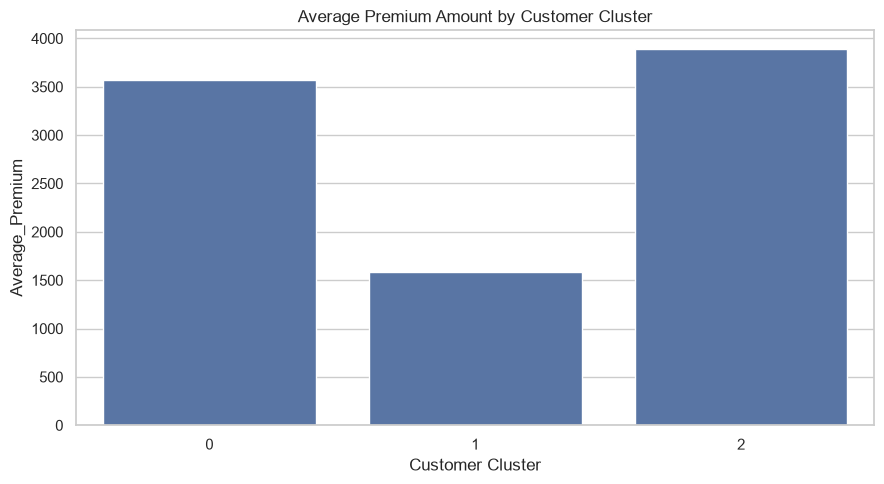

,Customer Segment,Marketing Strategy,Business Goal
0,High Premium Customers,"Offer suitable premium plans, personalized ser...",Improve retention and maintain premium revenue.
1,Medium Premium Customers,"Recommend suitable coverage upgrades, bundled ...",Increase engagement and encourage appropriate ...
2,Low Premium Customers,"Promote affordable plans, flexible payment opt...",Improve conversion while keeping products affo...


In [11]:
count_agg = ("Customer ID","count") if "Customer ID" in df.columns else ("Age","count")
unique_agg = ("Customer ID","nunique") if "Customer ID" in df.columns else ("Age","count")
cluster_insights = df.groupby("Customer Cluster").agg(
    Total_Records=count_agg, Unique_Customers=unique_agg,
    Average_Age=("Age","mean"), Average_Income=("Income Level","mean"),
    Average_Premium=("Premium Amount","mean"),
    Average_Coverage=("Coverage Amount","mean")
).round(2)

ordered = cluster_insights.sort_values("Average_Premium",ascending=False).index.tolist()
labels = ["High Premium Customers","Medium Premium Customers","Low Premium Customers"]
label_map = {cluster_id: labels[i] for i,cluster_id in enumerate(ordered)}
df["Business Segment"] = df["Customer Cluster"].map(label_map)
cluster_insights["Business Segment"] = cluster_insights.index.map(label_map)
display(cluster_insights)

plt.figure(figsize=(9,5))
sns.barplot(data=cluster_insights.reset_index(),x="Customer Cluster",y="Average_Premium")
plt.title("Average Premium Amount by Customer Cluster")
plt.tight_layout(); plt.show()

marketing_recommendations = pd.DataFrame({
    "Customer Segment":["High Premium Customers","Medium Premium Customers","Low Premium Customers"],
    "Marketing Strategy":[
        "Offer suitable premium plans, personalized service, and loyalty rewards.",
        "Recommend suitable coverage upgrades, bundled plans, and renewal reminders.",
        "Promote affordable plans, flexible payment options, and introductory offers."
    ],
    "Business Goal":[
        "Improve retention and maintain premium revenue.",
        "Increase engagement and encourage appropriate upgrades.",
        "Improve conversion while keeping products affordable."
    ]
})
display(marketing_recommendations)

## 12. Conclusion and Project Exports
Save the final dataset, cluster insights, marketing recommendations, and future-purchase test predictions when available.

In [12]:
df.to_csv("Customer_Segmentation_Final.csv", index=False)
cluster_insights.to_csv("Customer_Cluster_Insights.csv", index=True)
marketing_recommendations.to_csv("Customer_Marketing_Recommendations.csv", index=False)

print("Saved:")
print("- Customer_Segmentation_Final.csv")
print("- Customer_Cluster_Insights.csv")
print("- Customer_Marketing_Recommendations.csv")
if "purchase_model" in globals() and purchase_model is not None:
    print("- Future_Purchase_Predictions.csv (if Section 9 completed successfully)")

print("\nConclusion:")
print("K-Means was used to explore customer groups.")
print("Random Forest was evaluated for the existing segmentation label.")
print("The future-purchase model is exploratory and needs a better-defined target and time-based validation before real-world use.")

Saved:
- Customer_Segmentation_Final.csv
- Customer_Cluster_Insights.csv
- Customer_Marketing_Recommendations.csv
- Future_Purchase_Predictions.csv (if Section 9 completed successfully)

Conclusion:
K-Means was used to explore customer groups.
Random Forest was evaluated for the existing segmentation label.
The future-purchase model is exploratory and needs a better-defined target and time-based validation before real-world use.


In [13]:
%pip install sqlalchemy "psycopg[binary]"

   ---------------------------------------- 0.0/3.7 MB ? eta -:--:--
   -- ------------------------------------- 0.3/3.7 MB ? eta -:--:--
   ----- ---------------------------------- 0.5/3.7 MB 8.5 MB/s eta 0:00:01
   ----------- ---------------------------- 1.0/3.7 MB 1.9 MB/s eta 0:00:02
   ---------------------- ----------------- 2.1/3.7 MB 2.9 MB/s eta 0:00:01
   ---------------------------------- ----- 3.1/3.7 MB 3.5 MB/s eta 0:00:01
   ---------------------------------------- 3.7/3.7 MB 3.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:

import pandas as pd

file_path = r"C:\Users\ASUS\Downloads\customer_segmentation_data.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (53503, 20)


,Customer ID,Age,Gender,Marital Status,Education Level,Geographic Information,Occupation,Income Level,Behavioral Data,Purchase History,Interactions with Customer Service,Insurance Products Owned,Coverage Amount,Premium Amount,Policy Type,Customer Preferences,Preferred Communication Channel,Preferred Contact Time,Preferred Language,Segmentation Group
0,84966,23,Female,Married,Associate Degree,Mizoram,Entrepreneur,70541,policy5,04-10-2018,Phone,policy2,366603,2749,Group,Email,In-Person Meeting,Afternoon,English,Segment5
1,95568,26,Male,Widowed,Doctorate,Goa,Manager,54168,policy5,11-06-2018,Chat,policy1,780236,1966,Group,Mail,In-Person Meeting,Morning,French,Segment5
2,10544,29,Female,Single,Associate Degree,Rajasthan,Entrepreneur,73899,policy5,06-05-2021,Email,policy3,773926,4413,Group,Email,Mail,Evening,German,Segment3
3,77033,20,Male,Divorced,Bachelor's Degree,Sikkim,Entrepreneur,63381,policy5,09-02-2018,Chat,policy2,787815,4342,Family,Text,In-Person Meeting,Anytime,French,Segment3
4,88160,25,Female,Separated,Bachelor's Degree,West Bengal,Manager,38794,policy1,09-10-2018,Chat,policy4,366506,1276,Family,Email,Text,Weekends,English,Segment2


In [5]:

from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from getpass import getpass

# PostgreSQL connection details
username = "postgres"
password = getpass("210750")

connection_url = URL.create(
    "postgresql+psycopg2",
    username=username,
    password=password,
    host="localhost",
    port=5432,
    database="CustomerSegmentationDB"
)

# Create connection
engine = create_engine(connection_url)

# Upload the dataset to PostgreSQL
df.to_sql(
    name="customer_data",
    con=engine,
    schema="public",
    if_exists="replace",
    index=False
)

print("Dataset uploaded successfully to PostgreSQL!")


210750 ········


Dataset uploaded successfully to PostgreSQL!
